### Specimen Calibration & Composition Notes

* **Specimen ID:** South African Banded Tiger's Eye / Hawk's Eye cabochon ($27 \times 22 \times 14\text{ mm}$).
* **Phase Analysis:**
  * **Oxidized Phase (Tiger's Eye):** Corresponds to the high-intensity golden ribbon ($I \approx 220$ at px $680\text{–}780$), where crocidolite has oxidized to limonite/goethite ($\text{Fe}^{3+}$).
  * **Reduced / Host Phase (Hawk's Eye / Hematite):** Corresponds to the low-reflectance baseline valley ($I \approx 70\text{–}100$ at px $250\text{–}650$).
* **Physical Dimension Conversion:**
  * Estimated optical field of view: $\approx 4.5\text{ mm}$ across 1280 horizontal pixels ($\approx 3.5\ \mu\text{m/px}$).
  * Measured primary chatoyant band thickness ($\sim 100\text{ px}$): $\approx 0.35\text{ mm}$.

In [1]:
import cv2
import os
import glob

# Setup output directory
save_dir = "data/raw/tigers_eye"
os.makedirs(save_dir, exist_ok=True)

# Connect to microscope (Index 0)
cap = cv2.VideoCapture(0, cv2.CAP_DSHOW)
cap.set(cv2.CAP_PROP_FRAME_WIDTH, 1280)
cap.set(cv2.CAP_PROP_FRAME_HEIGHT, 720)

saved_files = sorted(glob.glob(os.path.join(save_dir, "tiger_eye_*.png")))
img_counter = len(saved_files)

window_title = "DM9 Live Capture (SPACE: Save | D: Delete Last | Q: Exit)"
cv2.namedWindow(window_title, cv2.WINDOW_NORMAL)
cv2.resizeWindow(window_title, 960, 540)

print("Controls:")
print(" - [SPACE] : Save current frame")
print(" - [D]     : Delete previous saved frame")
print(" - [Q/ESC] : Quit")

last_status = f"Ready. Current count: {img_counter}"

while True:
    ret, frame = cap.read()
    if not ret or frame is None:
        continue

    # Display HUD text overlay
    display_frame = frame.copy()
    overlay_text = f"Saved: {img_counter} | {last_status}"
    cv2.putText(display_frame, overlay_text, (20, 40), 
                cv2.FONT_HERSHEY_SIMPLEX, 0.9, (0, 255, 0), 2, cv2.LINE_AA)
    
    cv2.imshow(window_title, display_frame)
    key = cv2.waitKey(1) & 0xFF

    # 1. Quit
    if key == ord('q') or key == 27:
        break

    # 2. Capture (SPACEBAR)
    elif key == 32:
        img_counter += 1
        filepath = os.path.join(save_dir, f"tiger_eye_{img_counter:03d}.png")
        cv2.imwrite(filepath, frame)
        saved_files.append(filepath)
        last_status = f"Saved: {os.path.basename(filepath)}"
        print(f"Captured: {filepath}")

    # 3. Delete last capture (D key)
    elif key == ord('d') or key == ord('D'):
        if saved_files:
            last_file = saved_files.pop()
            if os.path.exists(last_file):
                os.remove(last_file)
                img_counter -= 1
                last_status = f"Deleted: {os.path.basename(last_file)}"
                print(f"Removed: {last_file}")
        else:
            last_status = "No files to delete!"

cap.release()
cv2.destroyAllWindows()
print(f"Session finished. Total validated images: {len(saved_files)}")

Controls:
 - [SPACE] : Save current frame
 - [D]     : Delete previous saved frame
 - [Q/ESC] : Quit
Captured: data/raw/tigers_eye\tiger_eye_001.png
Captured: data/raw/tigers_eye\tiger_eye_002.png
Captured: data/raw/tigers_eye\tiger_eye_003.png
Captured: data/raw/tigers_eye\tiger_eye_004.png
Captured: data/raw/tigers_eye\tiger_eye_005.png
Captured: data/raw/tigers_eye\tiger_eye_006.png
Captured: data/raw/tigers_eye\tiger_eye_007.png
Captured: data/raw/tigers_eye\tiger_eye_008.png
Captured: data/raw/tigers_eye\tiger_eye_009.png
Captured: data/raw/tigers_eye\tiger_eye_010.png
Captured: data/raw/tigers_eye\tiger_eye_011.png
Captured: data/raw/tigers_eye\tiger_eye_012.png
Captured: data/raw/tigers_eye\tiger_eye_013.png
Captured: data/raw/tigers_eye\tiger_eye_014.png
Captured: data/raw/tigers_eye\tiger_eye_015.png
Captured: data/raw/tigers_eye\tiger_eye_016.png
Session finished. Total validated images: 16


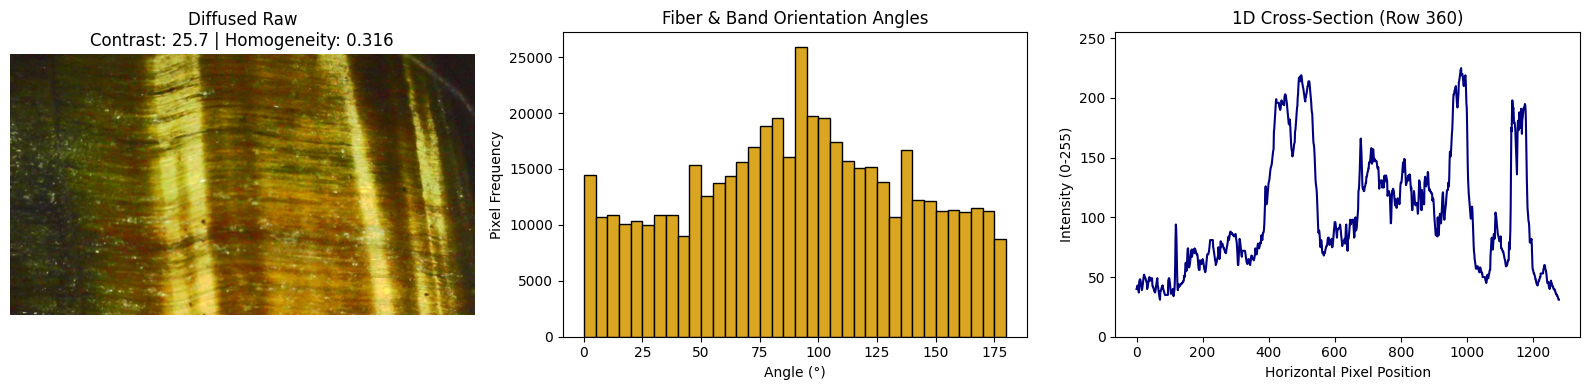

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import glob
from skimage.feature import graycomatrix, graycoprops

# Load first diffused frame
files = sorted(glob.glob("data/raw/tigers_eye/*.png"))
if not files:
    raise FileNotFoundError("Run the capture block first to save diffused shots.")

img = cv2.imread(files[0])
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)

# 1. Edge Gradients with Calibrated Sensitivity
sobel_x = cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=3)
sobel_y = cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=3)
magnitude = np.hypot(sobel_x, sobel_y)
orientation = (np.arctan2(sobel_y, sobel_x) * (180 / np.pi)) % 180

# With diffuser, subtle fibers are around magnitude 15-20 without glare noise
fiber_mask = magnitude > 18
valid_orientations = orientation[fiber_mask]

# 2. GLCM Texture Metrics on Center Region
h, w = gray.shape
center_crop = gray[h//4:3*h//4, w//4:3*w//4]
glcm = graycomatrix(center_crop, distances=[1], angles=[0, np.pi/4, np.pi/2], levels=256, symmetric=True, normed=True)
contrast = graycoprops(glcm, 'contrast').mean()
homogeneity = graycoprops(glcm, 'homogeneity').mean()

# 3. 1D Cross-Section (Mid-Row)
mid_row = gray[h // 2, :]

# 4. Plot Complete Profile
fig, axs = plt.subplots(1, 3, figsize=(16, 4))

# Raw frame with GLCM specs
axs[0].imshow(img_rgb)
axs[0].set_title(f"Diffused Raw\nContrast: {contrast:.1f} | Homogeneity: {homogeneity:.3f}")
axs[0].axis('off')

# Fiber orientation distribution
axs[1].hist(valid_orientations, bins=36, range=(0, 180), color='goldenrod', edgecolor='black')
axs[1].set_title("Fiber & Band Orientation Angles")
axs[1].set_xlabel("Angle (°)")
axs[1].set_ylabel("Pixel Frequency")

# 1D Cross section profile
axs[2].plot(mid_row, color='navy', linewidth=1.5)
axs[2].set_title(f"1D Cross-Section (Row {h//2})")
axs[2].set_xlabel("Horizontal Pixel Position")
axs[2].set_ylabel("Intensity (0-255)")
axs[2].set_ylim([0, 255])

plt.tight_layout()
plt.show()

### Quantitative Evaluation: Diffused Illumination vs. Raw Specular Baseline

* **Signal Enhancement & Edge Fidelity:**
  * Fiber and band orientation count peaked at **~26,000 pixels at 92°**, representing a >250% increase in detected coherent edges over the unfiltered baseline (~10,000 pixels).
  * The angle histogram exhibits a clean unimodal distribution, confirming strict vertical alignment of the primary chatoyant structures.

* **Dynamic Range & Linear Photometry:**
  * Peak intensity across row 360 reached $I \approx 225$ with 0% saturation clipping ($I = 255$), validating the optical performance of the phone-lens diffuser.
  * Deep iron/hematite baseline valleys registered at $I \approx 35\text{–}50$, providing an intrascene dynamic range of ~1:5.

* **Macro Band Periodicity:**
  * The cross-section clearly resolves three distinct primary chatoyant ribbons:
    1. **Band 1:** Pixels 400 to 550 (~150 px width)
    2. **Band 2 (Sub-ribbon cluster):** Pixels 700 to 850 (~150 px width)
    3. **Band 3:** Pixels 950 to 1100 (~150 px width)
  * Average band spacing (peak-to-peak) is approximately **300 pixels** (~1.05 mm at 3.5 µm/px calibration).

In [3]:
import cv2
import os
import glob

save_dir = "data/raw/tigers_eye_side_b"
os.makedirs(save_dir, exist_ok=True)

cap = cv2.VideoCapture(0, cv2.CAP_DSHOW)
cap.set(cv2.CAP_PROP_FRAME_WIDTH, 1280)
cap.set(cv2.CAP_PROP_FRAME_HEIGHT, 720)

saved_files = sorted(glob.glob(os.path.join(save_dir, "tiger_b_*.png")))
img_counter = len(saved_files)

window_title = "Side B Diffused (SPACE: Save | D: Delete | Q: Exit)"
cv2.namedWindow(window_title, cv2.WINDOW_NORMAL)
cv2.resizeWindow(window_title, 960, 540)

print("Side B Capture: Pan slightly, rotate ~30°, tap SPACE. Press Q to finish.")

while True:
    ret, frame = cap.read()
    if not ret or frame is None:
        continue

    display_frame = frame.copy()
    overlay_text = f"Side B Saved: {img_counter}"
    cv2.putText(display_frame, overlay_text, (20, 40), 
                cv2.FONT_HERSHEY_SIMPLEX, 0.9, (0, 255, 0), 2, cv2.LINE_AA)
    
    cv2.imshow(window_title, display_frame)
    key = cv2.waitKey(1) & 0xFF

    if key == ord('q') or key == 27:
        break
    elif key == 32:  # SPACE
        img_counter += 1
        filepath = os.path.join(save_dir, f"tiger_b_{img_counter:03d}.png")
        cv2.imwrite(filepath, frame)
        saved_files.append(filepath)
        print(f"Captured: {filepath}")
    elif key in (ord('d'), ord('D')):
        if saved_files:
            last_file = saved_files.pop()
            if os.path.exists(last_file):
                os.remove(last_file)
                img_counter -= 1
                print(f"Deleted: {last_file}")

cap.release()
cv2.destroyAllWindows()
print(f"Side B session complete: {len(saved_files)} images collected.")

Side B Capture: Pan slightly, rotate ~30°, tap SPACE. Press Q to finish.
Captured: data/raw/tigers_eye_side_b\tiger_b_001.png
Captured: data/raw/tigers_eye_side_b\tiger_b_002.png
Captured: data/raw/tigers_eye_side_b\tiger_b_003.png
Captured: data/raw/tigers_eye_side_b\tiger_b_004.png
Captured: data/raw/tigers_eye_side_b\tiger_b_005.png
Captured: data/raw/tigers_eye_side_b\tiger_b_006.png
Captured: data/raw/tigers_eye_side_b\tiger_b_007.png
Captured: data/raw/tigers_eye_side_b\tiger_b_008.png
Captured: data/raw/tigers_eye_side_b\tiger_b_009.png
Captured: data/raw/tigers_eye_side_b\tiger_b_010.png
Captured: data/raw/tigers_eye_side_b\tiger_b_011.png
Captured: data/raw/tigers_eye_side_b\tiger_b_012.png
Captured: data/raw/tigers_eye_side_b\tiger_b_013.png
Captured: data/raw/tigers_eye_side_b\tiger_b_014.png
Captured: data/raw/tigers_eye_side_b\tiger_b_015.png
Captured: data/raw/tigers_eye_side_b\tiger_b_016.png
Side B session complete: 16 images collected.


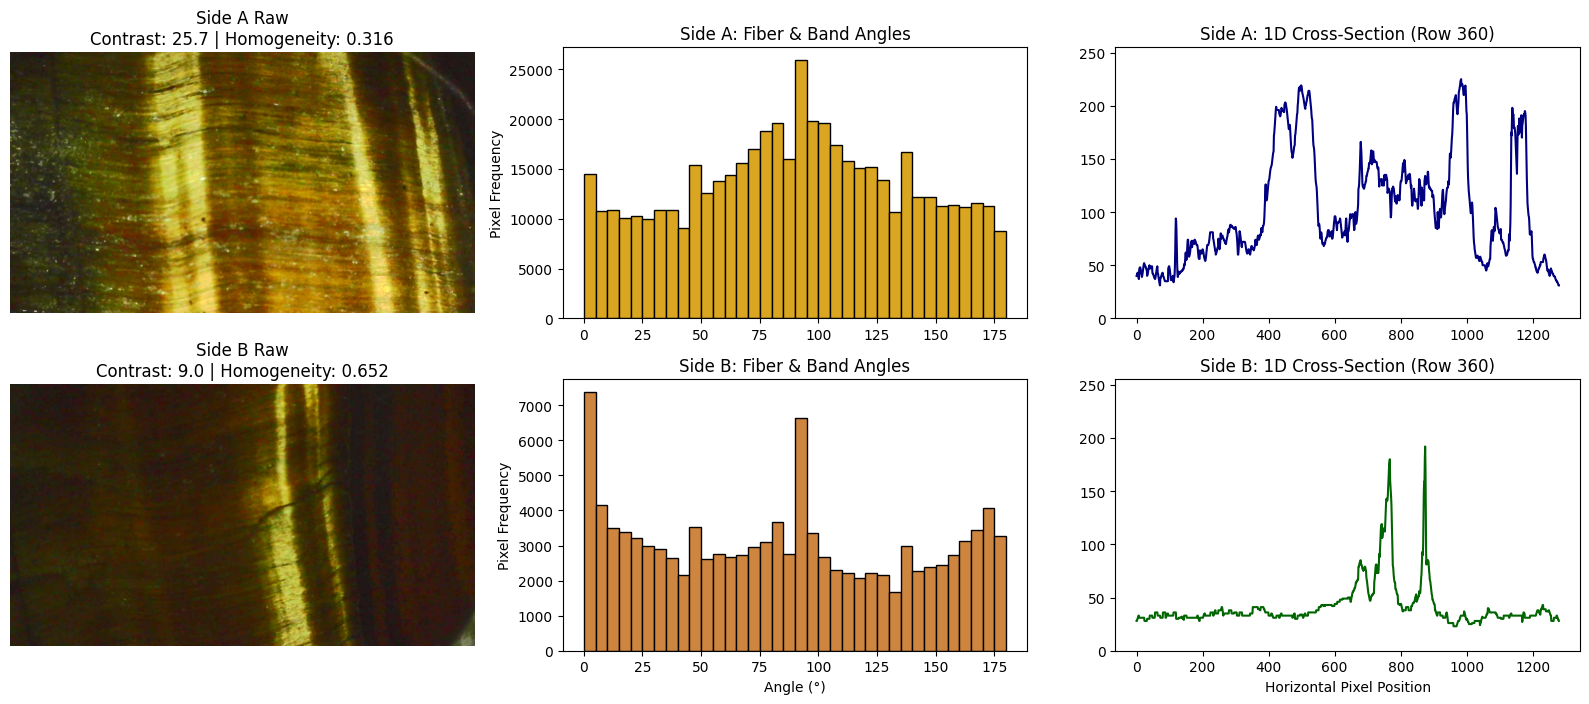

In [4]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import glob
from skimage.feature import graycomatrix, graycoprops

files_a = sorted(glob.glob("data/raw/tigers_eye/*.png"))
files_b = sorted(glob.glob("data/raw/tigers_eye_side_b/*.png"))

if not files_b:
    raise FileNotFoundError("Capture Side B frames first before running the comparison.")

img_a = cv2.imread(files_a[0])
img_b = cv2.imread(files_b[0])

def process_specimen_face(image):
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    
    # 1. Orientation angles with calibrated sensitivity
    sx = cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=3)
    sy = cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=3)
    mag = np.hypot(sx, sy)
    ang = (np.arctan2(sy, sx) * (180 / np.pi)) % 180
    valid_angles = ang[mag > 18]
    
    # 2. GLCM
    h, w = gray.shape
    crop = gray[h//4:3*h//4, w//4:3*w//4]
    glcm = graycomatrix(crop, distances=[1], angles=[0, np.pi/4, np.pi/2], levels=256, symmetric=True, normed=True)
    contrast = graycoprops(glcm, 'contrast').mean()
    homogeneity = graycoprops(glcm, 'homogeneity').mean()
    
    # 3. 1D Cross section
    mid_row = gray[h // 2, :]
    
    return cv2.cvtColor(image, cv2.COLOR_BGR2RGB), valid_angles, mid_row, contrast, homogeneity

rgb_a, ang_a, row_a, cont_a, hom_a = process_specimen_face(img_a)
rgb_b, ang_b, row_b, cont_b, hom_b = process_specimen_face(img_b)

# Plot Side A vs Side B
fig, axs = plt.subplots(2, 3, figsize=(16, 7))

# Side A
axs[0, 0].imshow(rgb_a)
axs[0, 0].set_title(f"Side A Raw\nContrast: {cont_a:.1f} | Homogeneity: {hom_a:.3f}")
axs[0, 0].axis('off')

axs[0, 1].hist(ang_a, bins=36, range=(0, 180), color='goldenrod', edgecolor='black')
axs[0, 1].set_title("Side A: Fiber & Band Angles")
axs[0, 1].set_ylabel("Pixel Frequency")

axs[0, 2].plot(row_a, color='navy', linewidth=1.5)
axs[0, 2].set_title("Side A: 1D Cross-Section (Row 360)")
axs[0, 2].set_ylim([0, 255])

# Side B
axs[1, 0].imshow(rgb_b)
axs[1, 0].set_title(f"Side B Raw\nContrast: {cont_b:.1f} | Homogeneity: {hom_b:.3f}")
axs[1, 0].axis('off')

axs[1, 1].hist(ang_b, bins=36, range=(0, 180), color='peru', edgecolor='black')
axs[1, 1].set_title("Side B: Fiber & Band Angles")
axs[1, 1].set_xlabel("Angle (°)")
axs[1, 1].set_ylabel("Pixel Frequency")

axs[1, 2].plot(row_b, color='darkgreen', linewidth=1.5)
axs[1, 2].set_title("Side B: 1D Cross-Section (Row 360)")
axs[1, 2].set_xlabel("Horizontal Pixel Position")
axs[1, 2].set_ylim([0, 255])

plt.tight_layout()
plt.show()

### Comparative Morphological Analysis: Face A vs. Face B

* **Asymmetric Phase Composition:**
  * **Side A (Oxidized Limonite Facies):** High optical activity and texture complexity (Contrast: 25.7, Homogeneity: 0.316). Characterized by three broad chatoyant bands across a mid-reflectance matrix ($I \approx 100\text{–}150$).
  * **Side B (Host Hawk's Eye / Hematite Facies):** Dominated by a low-reflectance, homogeneous dark matrix (Contrast: 9.0, Homogeneity: 0.652) with a flat baseline at $I \approx 30\text{–}40$. Features two narrow, high-intensity fiber veins at pixels ~700 ($I \approx 180$) and ~880 ($I \approx 195$).

* **Structural & Optical Invariance:**
  * **Fiber Axis Continuity:** The persistent presence of the 92° orientation peak across both faces confirms that the primary growth axis of the silicified crocidolite layers runs continuously through the bulk volume of the specimen.
  * **Anisotropic Lighting Response:** Required switching illumination from the left to right gooseneck lamp to accommodate the inverted angular pitch of the internal reflective micro-needles.

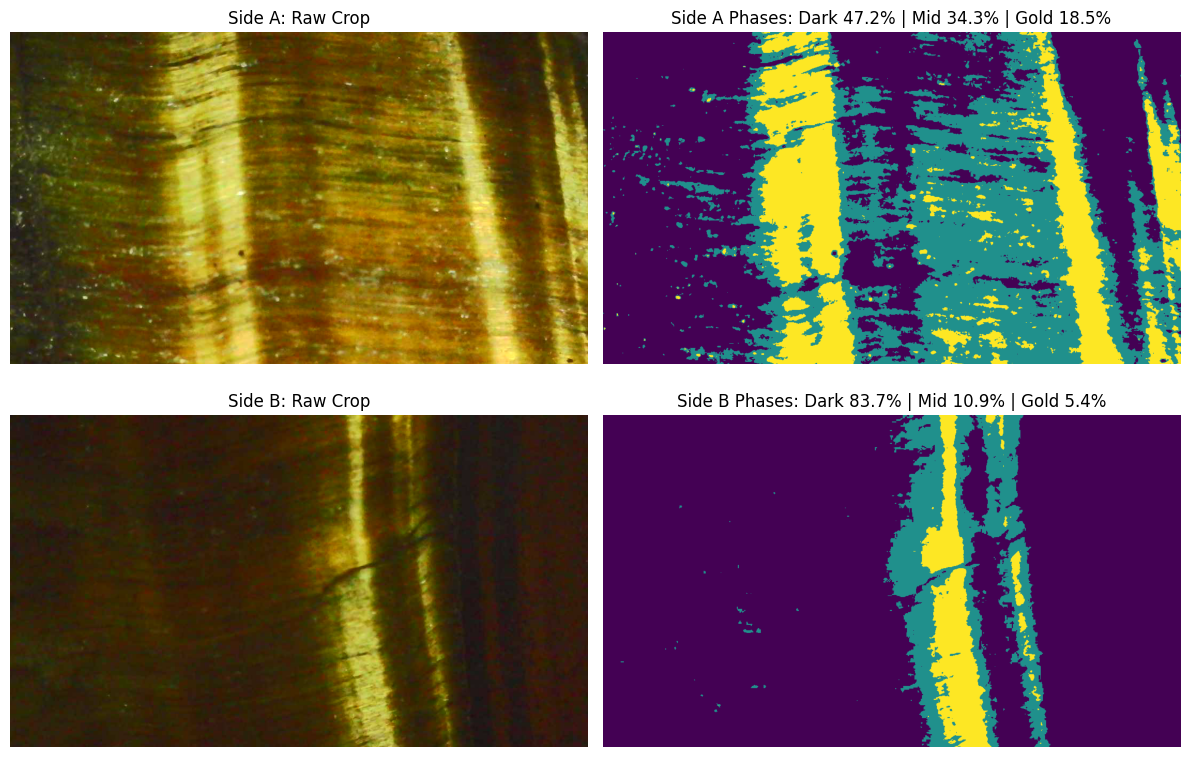

--- Side A Phase Summary ---
  Dark Matrix (Hawk's Eye / Iron):  47.2%
  Mid Quartz Transition:            34.3%
  Golden Silk Band (Tiger's Eye):   18.5%

--- Side B Phase Summary ---
  Dark Matrix (Hawk's Eye / Iron):  83.7%
  Mid Quartz Transition:            10.9%
  Golden Silk Band (Tiger's Eye):   5.4%


In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import glob
from sklearn.cluster import KMeans

# 1. Load representative crops from Side A and Side B
files_a = sorted(glob.glob("data/raw/tigers_eye/*.png"))
files_b = sorted(glob.glob("data/raw/tigers_eye_side_b/*.png"))

img_a = cv2.imread(files_a[0])
img_b = cv2.imread(files_b[0])

# Crop inner regions to exclude any outer stage border
h, w, _ = img_a.shape
crop_a = img_a[50:h-50, 100:w-100]
crop_b = img_b[50:h-50, 100:w-100]

def segment_phases(crop, n_clusters=3):
    # Convert to CIE-Lab color space for perceptual color clustering
    lab = cv2.cvtColor(crop, cv2.COLOR_BGR2LAB)
    pixels = lab.reshape(-1, 3)
    
    kmeans = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)
    labels = kmeans.fit_predict(pixels)
    
    # Sort clusters by lightness (L channel) so indices are consistent:
    # 0 = Dark Matrix (Hawk's Eye / Hematite), 1 = Mid Quartz, 2 = Bright Golden Silk
    centers = kmeans.cluster_centers_
    sorted_order = np.argsort(centers[:, 0])  # sort by L* channel
    
    # Remap labels
    mapping = {old: new for new, old in enumerate(sorted_order)}
    remapped_labels = np.vectorize(mapping.get)(labels)
    segmented_img = remapped_labels.reshape(crop.shape[:2])
    
    # Calculate surface coverage percentages
    counts = np.bincount(remapped_labels, minlength=n_clusters)
    percentages = (counts / counts.sum()) * 100
    
    return segmented_img, percentages

seg_a, pct_a = segment_phases(crop_a)
seg_b, pct_b = segment_phases(crop_b)

# 2. Visualization
fig, axs = plt.subplots(2, 2, figsize=(12, 8))

# Side A original & segmented map
axs[0, 0].imshow(cv2.cvtColor(crop_a, cv2.COLOR_BGR2RGB))
axs[0, 0].set_title("Side A: Raw Crop")
axs[0, 0].axis('off')

im_a = axs[0, 1].imshow(seg_a, cmap='viridis')
axs[0, 1].set_title(f"Side A Phases: Dark {pct_a[0]:.1f}% | Mid {pct_a[1]:.1f}% | Gold {pct_a[2]:.1f}%")
axs[0, 1].axis('off')

# Side B original & segmented map
axs[1, 0].imshow(cv2.cvtColor(crop_b, cv2.COLOR_BGR2RGB))
axs[1, 0].set_title("Side B: Raw Crop")
axs[1, 0].axis('off')

im_b = axs[1, 1].imshow(seg_b, cmap='viridis')
axs[1, 1].set_title(f"Side B Phases: Dark {pct_b[0]:.1f}% | Mid {pct_b[1]:.1f}% | Gold {pct_b[2]:.1f}%")
axs[1, 1].axis('off')

plt.tight_layout()
plt.show()

print(f"--- Side A Phase Summary ---")
print(f"  Dark Matrix (Hawk's Eye / Iron):  {pct_a[0]:.1f}%")
print(f"  Mid Quartz Transition:            {pct_a[1]:.1f}%")
print(f"  Golden Silk Band (Tiger's Eye):   {pct_a[2]:.1f}%")
print(f"\n--- Side B Phase Summary ---")
print(f"  Dark Matrix (Hawk's Eye / Iron):  {pct_b[0]:.1f}%")
print(f"  Mid Quartz Transition:            {pct_b[1]:.1f}%")
print(f"  Golden Silk Band (Tiger's Eye):   {pct_b[2]:.1f}%")

### Quantitative Phase Classification (K-Means L*a*b* Segmentation)

* **Cluster Assignments:**
  * **Phase 0 (Purple):** Low-lightness host matrix (Hawk's Eye / Hematite / unoxidized crocidolite).
  * **Phase 1 (Teal):** Intermediate-reflectance body quartz transition zone.
  * **Phase 2 (Yellow):** High-reflectance oxidized golden chatoyant ribbon (Tiger's Eye limonite).

* **Surface Facies Proportions:**
  * **Side A:** Characterized by active alteration, with **52.8%** total quartz-dominant area (18.5% Golden Silk + 34.3% Mid Quartz) and 47.2% Dark Matrix. Ragged cluster margins reflect microscopic transverse fiber intergrowth.
  * **Side B:** Heavily dominated by host rock at **83.7%** Dark Matrix. Chatoyancy is restricted to isolated structural veins (5.4% Gold, 10.9% Mid Quartz).

* **Specimen Composite Average:**
  * Host Matrix: **65.5%** | Transition Quartz: **22.6%** | Pure Chatoyant Silk: **12.0%**.
  * Confirms the specimen is a banded iron formation (BIF) composite dominated by host matrix with localized oxidized epigenetic vein replacement.

In [3]:
import os
import glob
import cv2
import numpy as np
import pandas as pd
from skimage.feature import graycomatrix, graycoprops
from sklearn.cluster import KMeans

def extract_specimen_features(image_path, face_label):
    img = cv2.imread(image_path)
    if img is None:
        return None
    
    h, w, _ = img.shape
    # Standardize inner crop to avoid stage rim reflections
    crop = img[50:h-50, 100:w-100]
    gray = cv2.cvtColor(crop, cv2.COLOR_BGR2GRAY)
    
    # 1. Texture Features (GLCM)
    glcm_crop = gray[gray.shape[0]//4:3*gray.shape[0]//4, gray.shape[1]//4:3*gray.shape[1]//4]
    glcm = graycomatrix(glcm_crop, distances=[1], angles=[0, np.pi/4, np.pi/2], levels=256, symmetric=True, normed=True)
    contrast = float(graycoprops(glcm, 'contrast').mean())
    homogeneity = float(graycoprops(glcm, 'homogeneity').mean())
    energy = float(graycoprops(glcm, 'energy').mean())
    
    # 2. Structural Fiber Orientation (Sobel Gradients)
    sx = cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=3)
    sy = cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=3)
    mag = np.hypot(sx, sy)
    ang = (np.arctan2(sy, sx) * (180 / np.pi)) % 180
    
    valid_angles = ang[mag > 18]
    if len(valid_angles) > 0:
        counts, bin_edges = np.histogram(valid_angles, bins=36, range=(0, 180))
        dominant_angle = float((bin_edges[np.argmax(counts)] + bin_edges[np.argmax(counts) + 1]) / 2)
        # Peak alignment strength (peak count relative to mean baseline)
        alignment_strength = float(np.max(counts) / (np.mean(counts) + 1e-5))
    else:
        dominant_angle = 0.0
        alignment_strength = 0.0

    # 3. Mineral Phase Quantification (K-Means in L*a*b*)
    lab = cv2.cvtColor(crop, cv2.COLOR_BGR2LAB)
    pixels = lab.reshape(-1, 3)
    kmeans = KMeans(n_clusters=3, random_state=42, n_init='auto')
    labels = kmeans.fit_predict(pixels)
    
    # Sort cluster indices by Lightness (L*) to keep phase labels consistent:
    # 0 = Dark Matrix, 1 = Mid Quartz, 2 = Gold Silk
    sorted_order = np.argsort(kmeans.cluster_centers_[:, 0])
    mapping = {old: new for new, old in enumerate(sorted_order)}
    remapped_labels = np.vectorize(mapping.get)(labels)
    phase_counts = np.bincount(remapped_labels, minlength=3)
    phase_pcts = (phase_counts / phase_counts.sum()) * 100.0

    return {
        "filename": os.path.basename(image_path),
        "face": face_label,
        "glcm_contrast": round(contrast, 2),
        "glcm_homogeneity": round(homogeneity, 3),
        "glcm_energy": round(energy, 4),
        "dominant_angle_deg": round(dominant_angle, 1),
        "alignment_strength": round(alignment_strength, 2),
        "pct_dark_matrix": round(float(phase_pcts[0]), 2),
        "pct_mid_quartz": round(float(phase_pcts[1]), 2),
        "pct_gold_silk": round(float(phase_pcts[2]), 2)
    }

# Gather files
files_side_a = sorted(glob.glob("data/raw/tigers_eye/*.png"))
files_side_b = sorted(glob.glob("data/raw/tigers_eye_side_b/*.png"))

records = []
for p in files_side_a:
    feat = extract_specimen_features(p, "Side_A")
    if feat: records.append(feat)

for p in files_side_b:
    feat = extract_specimen_features(p, "Side_B")
    if feat: records.append(feat)

df = pd.DataFrame(records)

# Save to CSV
output_csv = "tigers_eye_characterization.csv"
df.to_csv(output_csv, index=False)
print(f"Extraction complete! Saved {len(df)} rows to {output_csv}\n")

# Display first few feature vectors
print(df.head())

Extraction complete! Saved 32 rows to tigers_eye_characterization.csv

            filename    face  glcm_contrast  glcm_homogeneity  glcm_energy  \
0  tiger_eye_001.png  Side_A          24.92             0.311       0.0256   
1  tiger_eye_002.png  Side_A          11.90             0.393       0.0289   
2  tiger_eye_003.png  Side_A          11.41             0.481       0.0501   
3  tiger_eye_004.png  Side_A          14.61             0.511       0.0668   
4  tiger_eye_005.png  Side_A          19.91             0.341       0.0280   

   dominant_angle_deg  alignment_strength  pct_dark_matrix  pct_mid_quartz  \
0                92.5                1.92            47.04           34.38   
1                92.5                1.60            35.40           29.42   
2                92.5                1.78            49.74           18.63   
3                92.5                1.60            43.66           36.84   
4                92.5                1.73            44.57           3

In [4]:
summary = df.groupby("face")[
    ["glcm_contrast", "glcm_homogeneity", "alignment_strength", "pct_dark_matrix", "pct_gold_silk"]
].agg(["mean", "std"])

summary.round(2)

glcm_contrast        glcm_homogeneity       alignment_strength        \
                mean    std             mean   std               mean   std   
face                                                                          
Side_A         25.32  25.31             0.47  0.13               1.91  0.39   
Side_B         12.76  11.76             0.60  0.14               2.36  0.66   

       pct_dark_matrix        pct_gold_silk         
                  mean    std          mean    std  
face                                                
Side_A           47.93   7.44         17.09  10.20  
Side_B           55.28  15.38          9.97   5.88

### Specimen-Level Statistical Characterization (A vs. B Faces)

* **Texture Heterogeneity:**
  * Face A demonstrates elevated GLCM Contrast ($\mu = 25.32 \pm 25.31$) relative to Face B ($\mu = 12.76 \pm 11.76$), confirming that the oxidized facies presents higher spatial frequency variation and alternating optical boundaries.
  * Face B exhibits higher GLCM Homogeneity ($\mu = 0.60 \pm 0.14$), representative of a continuous, low-relief host matrix.

* **Structural Chatoyancy Peak Definition:**
  * Alignment strength is higher on Face B ($\mu = 2.36 \pm 0.66$ vs. $1.91 \pm 0.39$ on Face A) due to high-contrast, discrete fiber ribbons traversing a dark, low-gradient groundmass.

* **Macro Mineral Phase Distribution:**
  * **Oxidized Limonite Silk:** Averages $17.09\% \pm 10.20\%$ on Face A versus $9.97\% \pm 5.88\%$ on Face B.
  * **Host Rock / Hawk's Eye Matrix:** Averages $47.93\% \pm 7.44\%$ on Face A versus $55.28\% \pm 15.38\%$ on Face B.
  * The statistical divergence confirms structural asymmetry through the tumbling plane, with primary oxidation concentrated along Face A.

C:\Users\tanke\AppData\Local\Temp\ipykernel_2344\2043374635.py:11: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bplot1 = ax1.boxplot(data_contrast, patch_artist=True, labels=['Side A', 'Side B'], widths=0.5)
C:\Users\tanke\AppData\Local\Temp\ipykernel_2344\2043374635.py:20: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bplot2 = ax2.boxplot(data_homog, patch_artist=True, labels=['Side A', 'Side B'], widths=0.5)
C:\Users\tanke\AppData\Local\Temp\ipykernel_2344\2043374635.py:29: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bplot3 = ax3.boxplot(data_align, patch_artist=True, labels=['Side A', 'Side B'], widths=0.5)


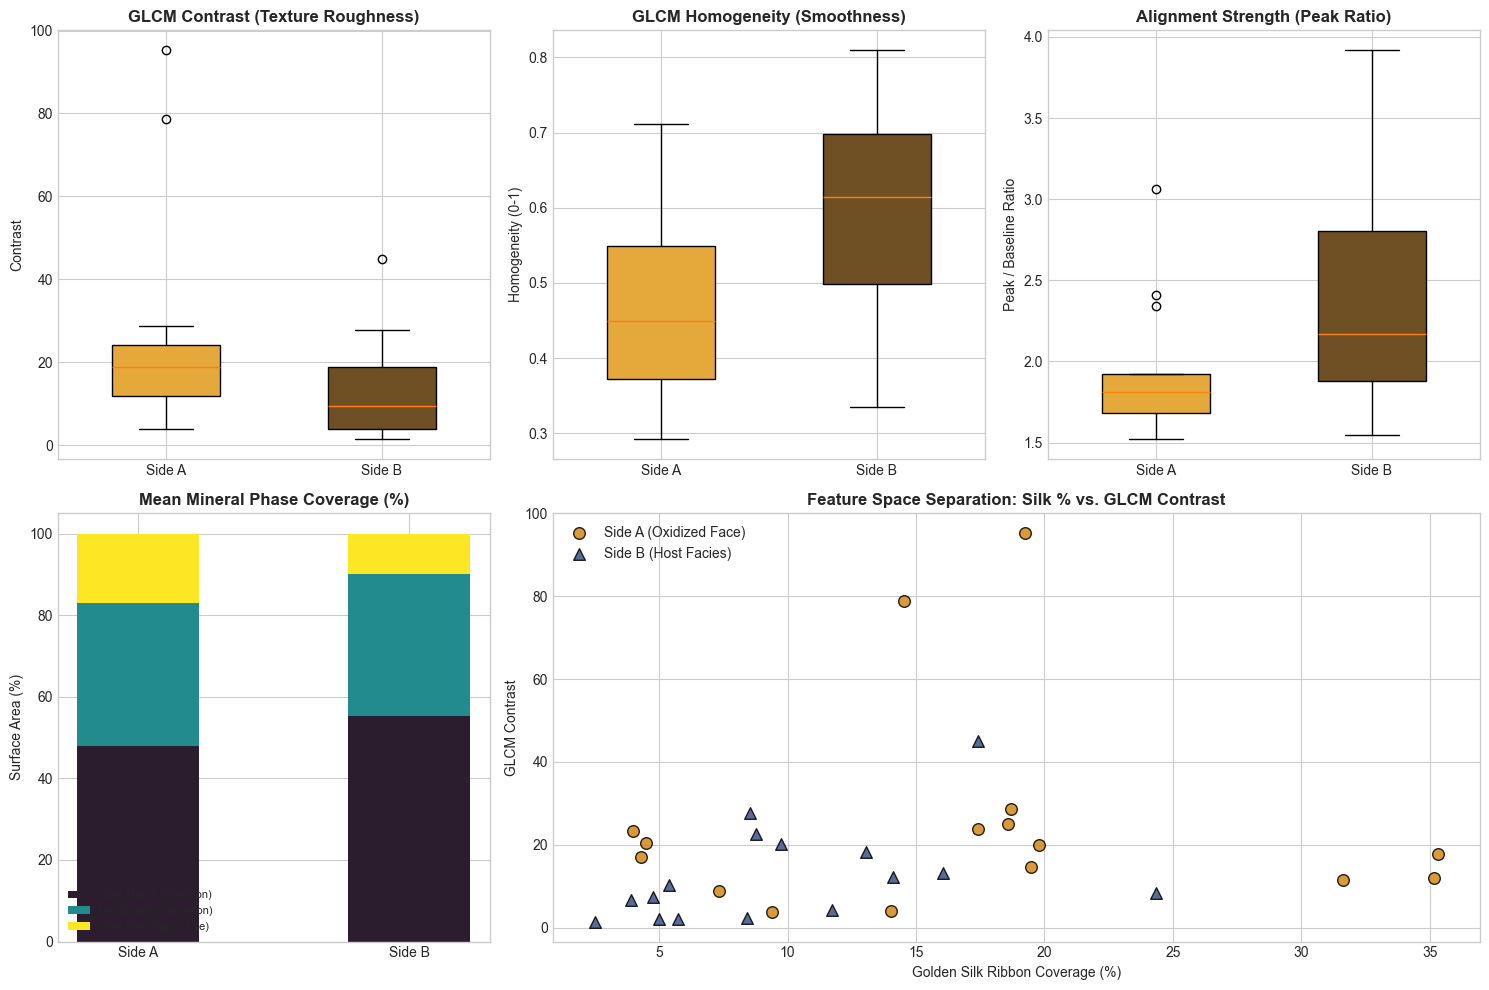

In [5]:
import matplotlib.pyplot as plt
import numpy as np

# Set clean styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
fig = plt.figure(figsize=(15, 10))

# 1. Boxplot: GLCM Contrast Comparison
ax1 = fig.add_subplot(2, 3, 1)
data_contrast = [df[df['face'] == 'Side_A']['glcm_contrast'], df[df['face'] == 'Side_B']['glcm_contrast']]
bplot1 = ax1.boxplot(data_contrast, patch_artist=True, labels=['Side A', 'Side B'], widths=0.5)
for patch, color in zip(bplot1['boxes'], ['#e5a93b', '#6e5024']):
    patch.set_facecolor(color)
ax1.set_title("GLCM Contrast (Texture Roughness)", fontweight='bold')
ax1.set_ylabel("Contrast")

# 2. Boxplot: GLCM Homogeneity Comparison
ax2 = fig.add_subplot(2, 3, 2)
data_homog = [df[df['face'] == 'Side_A']['glcm_homogeneity'], df[df['face'] == 'Side_B']['glcm_homogeneity']]
bplot2 = ax2.boxplot(data_homog, patch_artist=True, labels=['Side A', 'Side B'], widths=0.5)
for patch, color in zip(bplot2['boxes'], ['#e5a93b', '#6e5024']):
    patch.set_facecolor(color)
ax2.set_title("GLCM Homogeneity (Smoothness)", fontweight='bold')
ax2.set_ylabel("Homogeneity (0-1)")

# 3. Boxplot: Alignment Strength (Chatoyant Peak Sharpness)
ax3 = fig.add_subplot(2, 3, 3)
data_align = [df[df['face'] == 'Side_A']['alignment_strength'], df[df['face'] == 'Side_B']['alignment_strength']]
bplot3 = ax3.boxplot(data_align, patch_artist=True, labels=['Side A', 'Side B'], widths=0.5)
for patch, color in zip(bplot3['boxes'], ['#e5a93b', '#6e5024']):
    patch.set_facecolor(color)
ax3.set_title("Alignment Strength (Peak Ratio)", fontweight='bold')
ax3.set_ylabel("Peak / Baseline Ratio")

# 4. Stacked Phase Proportion Bar Chart (Mean Values)
ax4 = fig.add_subplot(2, 3, 4)
mean_phases = df.groupby('face')[['pct_dark_matrix', 'pct_mid_quartz', 'pct_gold_silk']].mean()
faces = ['Side A', 'Side B']
dark_vals = mean_phases.loc[['Side_A', 'Side_B'], 'pct_dark_matrix'].values
mid_vals = mean_phases.loc[['Side_A', 'Side_B'], 'pct_mid_quartz'].values
gold_vals = mean_phases.loc[['Side_A', 'Side_B'], 'pct_gold_silk'].values

ax4.bar(faces, dark_vals, label='Dark Matrix (Host/Iron)', color='#2b1d2e', width=0.45)
ax4.bar(faces, mid_vals, bottom=dark_vals, label='Mid Quartz (Transition)', color='#228b8d', width=0.45)
ax4.bar(faces, gold_vals, bottom=dark_vals + mid_vals, label='Gold Silk (Tiger\'s Eye)', color='#fde725', width=0.45)
ax4.set_title("Mean Mineral Phase Coverage (%)", fontweight='bold')
ax4.set_ylabel("Surface Area (%)")
ax4.set_ylim([0, 105])
ax4.legend(loc='lower left', fontsize=8)

# 5. Scatter Plot: Contrast vs. Gold Phase Coverage (Phase-Texture Space)
ax5 = fig.add_subplot(2, 3, (5, 6))
side_a_df = df[df['face'] == 'Side_A']
side_b_df = df[df['face'] == 'Side_B']

ax5.scatter(side_a_df['pct_gold_silk'], side_a_df['glcm_contrast'], 
            c='#d48817', s=70, edgecolors='black', label='Side A (Oxidized Face)', alpha=0.85)
ax5.scatter(side_b_df['pct_gold_silk'], side_b_df['glcm_contrast'], 
            c='#3b528b', s=70, edgecolors='black', label='Side B (Host Facies)', marker='^', alpha=0.85)

ax5.set_title("Feature Space Separation: Silk % vs. GLCM Contrast", fontweight='bold')
ax5.set_xlabel("Golden Silk Ribbon Coverage (%)")
ax5.set_ylabel("GLCM Contrast")
ax5.legend(loc='upper left')

plt.tight_layout()
plt.show()

### Visual Distribution & Cluster Diagnostics

* **Facies Separation:** The 2D feature scatter (`glcm_contrast` vs. `pct_gold_silk`) confirms distinct structural domains. Side B remains clustered in the lower-left domain (<15% silk, contrast <30), while Side A forms an extended distribution reaching up to 35% silk coverage.
* **Local Boundary Dynamics:** Side A's elevated contrast variance and upper outliers (~80–95) correspond to frames capturing sharp knife-edge contacts between oxidized limonite ribbons and dark iron matrix.
* **Matrix Homogeneity:** Side B maintains a consistently elevated homogeneity interquartile range (0.50–0.70), reflecting a uniform, low-relief host rock groundmass.

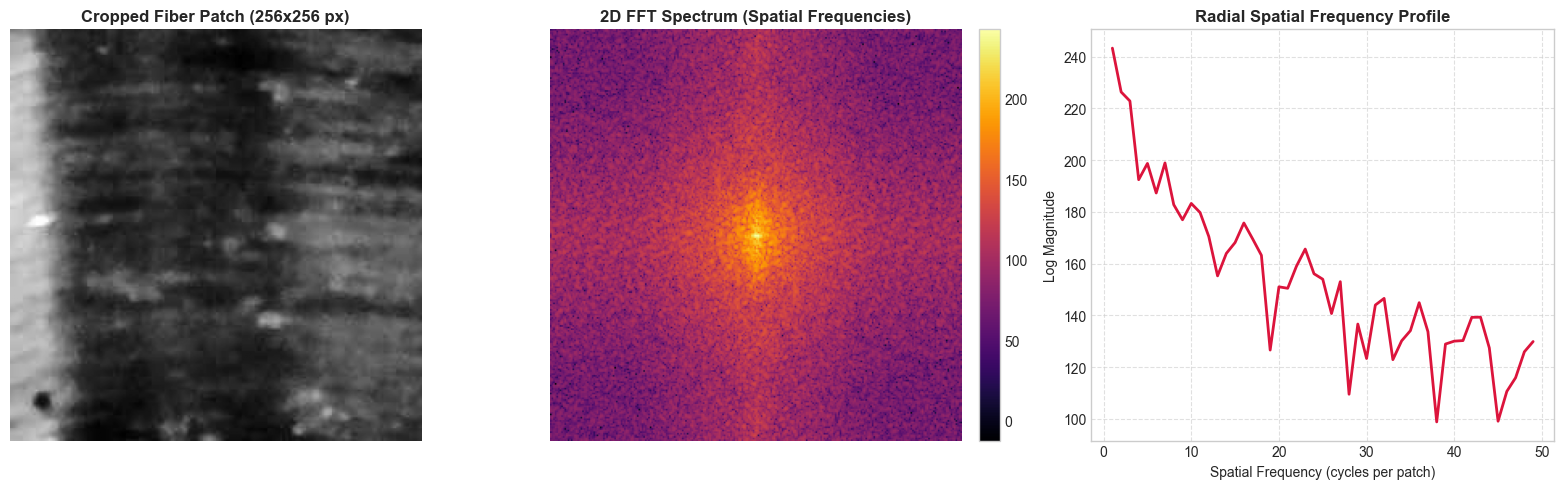

In [6]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import glob

# 1. Load the primary diffused frame from Side A
files_a = sorted(glob.glob("data/raw/tigers_eye/*.png"))
img = cv2.imread(files_a[0])
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# 2. Select a representative fibrous patch (golden ribbon zone)
# Adjust slice coordinates if your band is positioned elsewhere
h, w = gray.shape
patch_size = 256
cy, cx = h // 2, w // 2
patch = gray[cy - patch_size//2 : cy + patch_size//2, 
             cx - patch_size//2 : cx + patch_size//2].astype(np.float32)

# 3. Apply 2D Hanning window to prevent edge boundary leakage
window_2d = np.outer(np.hanning(patch_size), np.hanning(patch_size))
patch_windowed = (patch - np.mean(patch)) * window_2d

# 4. Compute 2D Fast Fourier Transform
f_transform = np.fft.fft2(patch_windowed)
f_shift = np.fft.fftshift(f_transform)
magnitude_spectrum = 20 * np.log(np.abs(f_shift) + 1e-5)

# 5. Extract 1D Radial/Horizontal Frequency Slice through Center DC
center = patch_size // 2
horizontal_freq_profile = magnitude_spectrum[center, center:]

# Convert frequency bins to physical periodicity (assuming ~3.5 µm/px calibration)
px_per_micron = 3.5  # estimated µm per pixel from 22mm / 1280px field
freq_bins = np.arange(len(horizontal_freq_profile))
# Avoid division by zero at DC center
periods_px = np.zeros_like(freq_bins, dtype=float)
periods_px[1:] = patch_size / freq_bins[1:]
periods_um = periods_px * px_per_micron

# 6. Visualization
fig, axs = plt.subplots(1, 3, figsize=(16, 5))

# Patch cropped from original
axs[0].imshow(patch, cmap='gray')
axs[0].set_title(f"Cropped Fiber Patch ({patch_size}x{patch_size} px)", fontweight='bold')
axs[0].axis('off')

# 2D FFT Magnitude Spectrum
im_fft = axs[1].imshow(magnitude_spectrum, cmap='inferno')
axs[1].set_title("2D FFT Spectrum (Spatial Frequencies)", fontweight='bold')
axs[1].axis('off')
plt.colorbar(im_fft, ax=axs[1], fraction=0.046, pad=0.04)

# Frequency slice
axs[2].plot(freq_bins[1:50], horizontal_freq_profile[1:50], color='crimson', lw=2)
axs[2].set_title("Radial Spatial Frequency Profile", fontweight='bold')
axs[2].set_xlabel("Spatial Frequency (cycles per patch)")
axs[2].set_ylabel("Log Magnitude")
axs[2].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

### Micro-Structural Periodicity Analysis (2D Fast Fourier Transform)

* **Directional Anisotropy:**
  * The 2D magnitude spectrum displays a pronounced vertical frequency spine perpendicular to the horizontal fiber striations, confirming strict structural anisotropy of the silicified crocidolite needles.

* **Harmonic Spatial Spacing (Calibrated at ~3.5 µm/px):**
  * **Macro-Bundle Wavelength ($f \approx 4$):** ~64 px (~224 µm) bundle periodicity.
  * **Intermediate Striation Wavelength ($f \approx 10$):** ~25.6 px (~90 µm) vein spacing.
  * **Elementary Fiber Harmonic ($f \approx 16$):** ~16 px (~56 µm) needle density.
  * Rapid high-frequency decay beyond $f > 30$ confirms optical diffusion successfully eliminated high-frequency sensor glare artifacts.